# Evaluación Sumativa 2
## Validación computacional de los resultados de S1 con weatherAUS

Se utilizan las tres medias, la proporción, Welch, chi-cuadrado y cuatro correlaciones de la Sumativa 1 adjunta. La decisión que se busca apoyar es la planificación de actividades agrícolas sensibles a lluvia; los escenarios son exploratorios y no pronósticos operativos.

Ejecute todo en orden. Requisitos: Python 3, numpy, pandas, scipy, matplotlib e IPython. Coloque el CSV junto al notebook o en `Dataset/`. Cada método utiliza 10.000 repeticiones y semillas independientes. Se generan tablas CSV, figuras y un archivo de resultados validados en `resultados_S2/`. La ejecución puede tomar varios minutos.

El remuestreo principal es iid por registros, para contrastar los intervalos clásicos de S1 bajo el mismo supuesto. No corrige dependencia temporal o espacial. Se añade sensibilidad por localidad y bloques localidad-mes; la coincidencia entre métodos iid no demuestra validez poblacional.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
import hashlib, json, sys, time
import scipy
SEED = 42
B = 10_000
assert B >= 10_000
OUT = Path('resultados_S2'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
def rng(i): return np.random.default_rng(np.random.SeedSequence([SEED,i]))
def guardar_fig(nombre):
    plt.tight_layout(); plt.savefig(OUT / (nombre+'.png'),bbox_inches='tight'); plt.show()
DATA_PATH = None  # Puede indicar aquí una ruta explícita.
if DATA_PATH is None:
    rutas=[p/n for p in [Path.cwd(),Path.cwd()/'Dataset',Path.cwd()/'upload',Path.cwd().parent/'Dataset']
           for n in ['weatherAUS(2).csv','weatherAUS.csv','weatherAUS(1).csv']]
    DATA_PATH=next((p for p in rutas if p.exists()),None)
if DATA_PATH is None: raise FileNotFoundError('Coloque el CSV junto al notebook o configure DATA_PATH.')
raw=pd.read_csv(DATA_PATH)
df=raw.copy()
print('Archivo:',DATA_PATH,'Dimensiones:',df.shape)
print('SHA256:',hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest())


Archivo: C:\Users\felip\weatherAUS.csv Dimensiones: (145460, 23)
SHA256: 573fd715cd69fcacc4df32024d823b450ae3edaae7e8ff2eeb623adbed424014


In [2]:
# ============================================================
# TRADUCCIÓN DE VARIABLES DEL DATASET weatherAUS
# ============================================================

# Renombrar columnas al español
df = df.rename(columns={
    "Date": "Fecha",
    "Location": "Ubicación",
    "MinTemp": "TemperaturaMínima",
    "MaxTemp": "TemperaturaMáxima",
    "Rainfall": "Lluvia",
    "Evaporation": "Evaporación",
    "Sunshine": "HorasSol",
    "WindGustDir": "DirecciónRáfagaViento",
    "WindGustSpeed": "VelocidadRáfagaViento",
    "WindDir9am": "DirecciónViento9am",
    "WindDir3pm": "DirecciónViento3pm",
    "WindSpeed9am": "VelocidadViento9am",
    "WindSpeed3pm": "VelocidadViento3pm",
    "Humidity9am": "Humedad9am",
    "Humidity3pm": "Humedad3pm",
    "Pressure9am": "Presión9am",
    "Pressure3pm": "Presión3pm",
    "Cloud9am": "Nubosidad9am",
    "Cloud3pm": "Nubosidad3pm",
    "Temp9am": "Temperatura9am",
    "Temp3pm": "Temperatura3pm",
    "RainToday": "LluviaHoy",
    "RainTomorrow": "LluviaMañana"
})

# Traducir valores categóricos Yes / No
if "LluviaHoy" in df.columns:
    df["LluviaHoy"] = df["LluviaHoy"].replace({
        "Yes": "Sí",
        "No": "No"
    })

if "LluviaMañana" in df.columns:
    df["LluviaMañana"] = df["LluviaMañana"].replace({
        "Yes": "Sí",
        "No": "No"
    })

# Verificar resultado
print("Columnas traducidas correctamente:\n")
print(df.columns.tolist())

print("\nDimensiones del dataset:")
print(df.shape)

print("\nPrimeras filas:")
display(df.head())

Columnas traducidas correctamente:

['Fecha', 'Ubicación', 'TemperaturaMínima', 'TemperaturaMáxima', 'Lluvia', 'Evaporación', 'HorasSol', 'DirecciónRáfagaViento', 'VelocidadRáfagaViento', 'DirecciónViento9am', 'DirecciónViento3pm', 'VelocidadViento9am', 'VelocidadViento3pm', 'Humedad9am', 'Humedad3pm', 'Presión9am', 'Presión3pm', 'Nubosidad9am', 'Nubosidad3pm', 'Temperatura9am', 'Temperatura3pm', 'LluviaHoy', 'LluviaMañana']

Dimensiones del dataset:
(145460, 23)

Primeras filas:


,Fecha,Ubicación,TemperaturaMínima,TemperaturaMáxima,Lluvia,Evaporación,HorasSol,DirecciónRáfagaViento,VelocidadRáfagaViento,DirecciónViento9am,...,Humedad9am,Humedad3pm,Presión9am,Presión3pm,Nubosidad9am,Nubosidad3pm,Temperatura9am,Temperatura3pm,LluviaHoy,LluviaMañana
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## 1 Resultados de referencia de S1

Se conserva la traducción original, sin imputación ni eliminación global. Cada estimación usa casos disponibles; cada correlación usa pares completos. Se recalculan los resultados a precisión completa con el CSV adjunto. Los intervalos clásicos se calculan como en S1 mediante aproximación normal. El 95 % se refiere a la cobertura del procedimiento en muestreos repetidos bajo sus supuestos, no a la probabilidad del parámetro fijo dentro del intervalo observado.

In [3]:
df['Fecha']=pd.to_datetime(df['Fecha'],errors='coerce')
df['LluviaMañana_bin']=df['LluviaMañana'].map({'No':0,'Sí':1})
PARAMS=['TemperaturaMáxima','Humedad3pm','Presión3pm','LluviaMañana_bin']
PAIRS=[('TemperaturaMáxima','Temperatura3pm'),('Presión9am','Presión3pm'),
       ('HorasSol','Nubosidad3pm'),('Humedad3pm','HorasSol')]
z=stats.norm.ppf(.975)
base=[]
for c in PARAMS:
    x=df[c].dropna().to_numpy(float); m=x.mean()
    se=np.sqrt(m*(1-m)/len(x)) if c.endswith('_bin') else x.std(ddof=1)/np.sqrt(len(x))
    base.append(dict(variable=c,n=len(x),estimacion_S1=m,clasico_inf=m-z*se,clasico_sup=m+z*se))
base=pd.DataFrame(base); display(base)
base.to_csv(OUT/'referencia_parametros_S1.csv',index=False)
h1=df.loc[df['LluviaMañana']=='Sí','Humedad3pm'].dropna().to_numpy()
h0=df.loc[df['LluviaMañana']=='No','Humedad3pm'].dropna().to_numpy()
t_s1,p_s1=stats.ttest_ind(h1,h0,equal_var=False)
cont=pd.crosstab(df['LluviaHoy'],df['LluviaMañana'])
chi_s1,p_chi_s1,gl,esp=stats.chi2_contingency(cont) # S1 usa corrección de Yates por defecto.
p_cond_si=cont.loc['Sí','Sí']/cont.loc['Sí'].sum()
p_cond_no=cont.loc['No','Sí']/cont.loc['No'].sum()
print(f'Welch S1: t={t_s1:.6f}; p={p_s1:.3e}; diferencia={h1.mean()-h0.mean():.6f}')
print(f'Chi-cuadrado S1 (Yates): {chi_s1:.6f}; p={p_chi_s1:.3e}')
refs=[]
for a,b in PAIRS:
    pares=df[[a,b]].dropna(); refs.append(dict(variable=a+' / '+b,n=len(pares),r_S1=pares.corr().iloc[0,1]))
referencias_corr=pd.DataFrame(refs); display(referencias_corr)
referencias_corr.to_csv(OUT/'referencia_correlaciones_S1.csv',index=False)
assert np.isclose(h1.mean(),68.80,atol=.01) and np.isclose(h0.mean(),46.51,atol=.01), 'El CSV difiere del resultado S1 adjunto.'


,variable,n,estimacion_S1,clasico_inf,clasico_sup
0,TemperaturaMáxima,144199,23.221348,23.184604,23.258092
1,Humedad3pm,140953,51.539116,51.430551,51.647681
2,Presión3pm,130432,1015.255889,1015.217697,1015.294081
3,LluviaMañana_bin,142193,0.224181,0.222014,0.226349


Welch S1: t=182.607693; p=0.000e+00; diferencia=22.289394
Chi-cuadrado S1 (Yates): 13799.479649; p=0.000e+00


,variable,n,r_S1
0,TemperaturaMáxima / Temperatura3pm,141589,0.984503
1,Presión9am / Presión3pm,130171,0.961326
2,HorasSol / Nubosidad3pm,65253,-0.703930
3,Humedad3pm / HorasSol,74497,-0.629130


## 2 Bootstrap no paramétrico de cuatro parámetros

Se generan 10.000 remuestras de tamaño n con reemplazo. Para reducir memoria y tiempo se muestrean **frecuencias multinomiales sobre los valores únicos**: esto es exactamente equivalente al bootstrap empírico por filas para una media, no una aproximación normal ni una reducción de muestra. Se procesan lotes de 100.

Se reutiliza la misma distribución para IC percentil y BCa. BCa ajusta sesgo y aceleración; esta última se obtiene del jackknife exacto de la media. Se usa la proporción de réplicas estrictamente menores para calcular el sesgo. El método no elimina sesgo por faltantes o dependencia.


,variable,n,estimacion_S1,clasico_inf,clasico_sup,percentil_inf,percentil_sup,BCa_inf,BCa_sup,error_bootstrap,sesgo_bootstrap,z0,aceleracion,B,ancho_clasico,ancho_percentil,ancho_BCa,ratio_BCa_clasico
0,TemperaturaMáxima,144199,23.221348,23.184604,23.258092,23.184938,23.258401,23.184943,23.258405,0.018682,0.000080,0.000501,0.000097,10000,0.073488,0.073462,0.073462,0.999638
1,Humedad3pm,140953,51.539116,51.430551,51.647681,51.428490,51.648333,51.427561,51.646831,0.055948,0.000173,-0.011531,0.000015,10000,0.217129,0.219843,0.219271,1.009861
2,Presión3pm,130432,1015.255889,1015.217697,1015.294081,1015.217936,1015.294419,1015.217939,1015.294432,0.019487,0.000096,0.000251,-0.000021,10000,0.076383,0.076483,0.076493,1.001435
3,LluviaMañana_bin,142193,0.224181,0.222014,0.226349,0.222022,0.226347,0.222034,0.226354,0.001095,-0.000005,0.002005,0.000585,10000,0.004335,0.004325,0.004321,0.996596


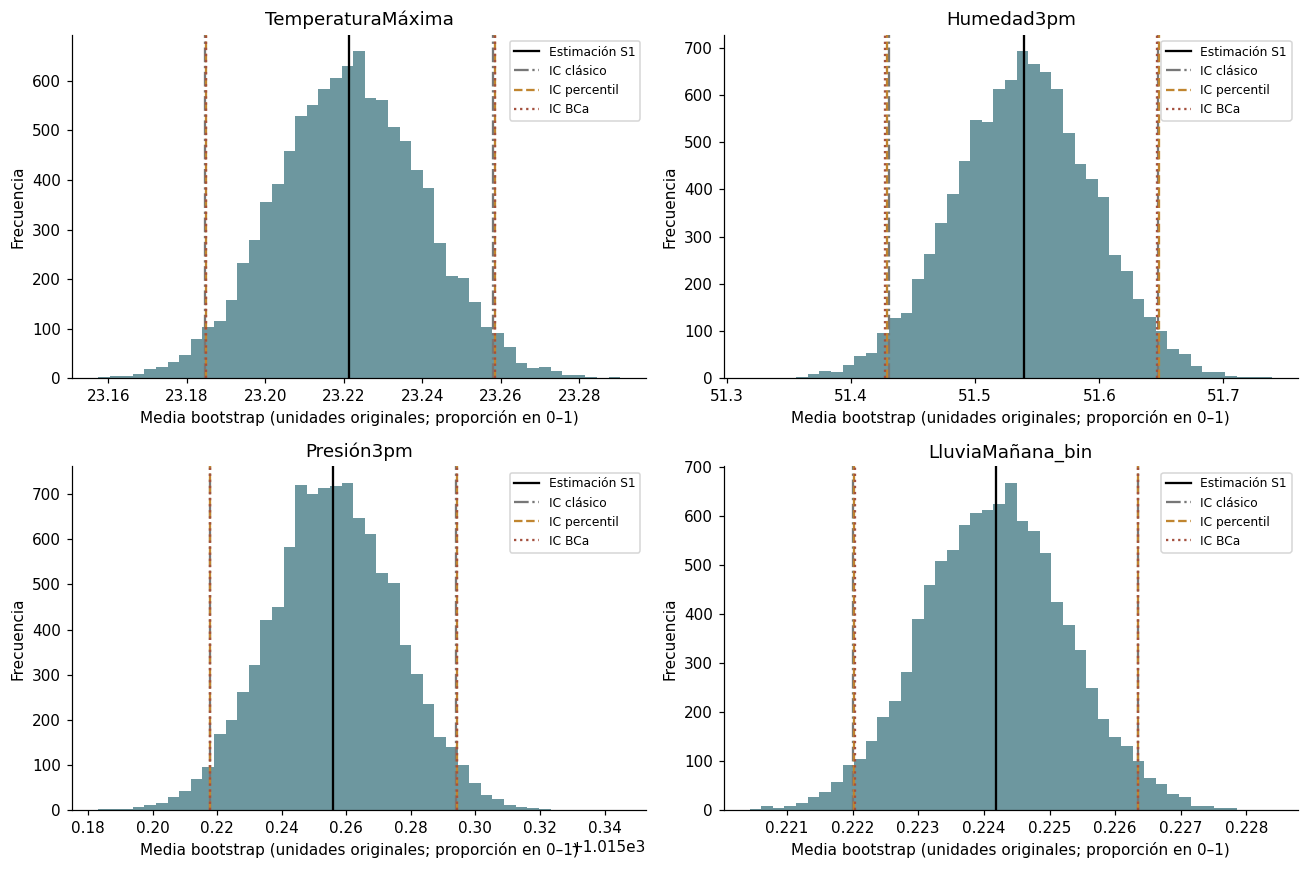

TemperaturaMáxima: razón de anchuras BCa/clásico=1.000; sesgo bootstrap=7.98433e-05.
Humedad3pm: razón de anchuras BCa/clásico=1.010; sesgo bootstrap=0.000173016.
Presión3pm: razón de anchuras BCa/clásico=1.001; sesgo bootstrap=9.60842e-05.
LluviaMañana_bin: razón de anchuras BCa/clásico=0.997; sesgo bootstrap=-4.8835e-06.
La cercanía de intervalos apoya concordancia bajo iid; no acredita independencia ni representatividad.


In [4]:
def bootstrap_media(x,B,gen):
    valores,cuentas=np.unique(x,return_counts=True)
    res=np.empty(B); n=len(x)
    for inicio in range(0,B,100):
        pesos=gen.multinomial(n,cuentas/n,size=min(100,B-inicio))
        res[inicio:inicio+len(pesos)]=(pesos@valores)/n
    return res

def bca_media(x,rep):
    m=x.mean(); n=len(x)
    jack=(x.sum()-x)/(n-1)
    u=jack.mean()-jack
    denom=6*np.sum(u*u)**1.5
    aceleracion=np.sum(u**3)/denom if denom>0 else 0.
    fraccion=np.mean(rep<m)
    z0=stats.norm.ppf(np.clip(fraccion,.5/len(rep),1-.5/len(rep)))
    zs=stats.norm.ppf([.025,.975])
    niveles=stats.norm.cdf(z0+(z0+zs)/(1-aceleracion*(z0+zs)))
    return np.quantile(rep,niveles),z0,aceleracion

boots={}; filas=[]
fig,axes=plt.subplots(2,2,figsize=(12,8))
for i,(c,ax) in enumerate(zip(PARAMS,axes.flat)):
    x=df[c].dropna().to_numpy(float)
    rep=bootstrap_media(x,B,rng(100+i)); boots[c]=rep
    per=np.quantile(rep,[.025,.975]); bc,z0,acc=bca_media(x,rep)
    r=base.loc[base.variable==c].iloc[0].to_dict()
    r.update(percentil_inf=per[0],percentil_sup=per[1],BCa_inf=bc[0],BCa_sup=bc[1],
             error_bootstrap=rep.std(ddof=1),sesgo_bootstrap=rep.mean()-x.mean(),z0=z0,aceleracion=acc,B=B)
    filas.append(r)
    ax.hist(rep,bins=45,color='#2f6b76',alpha=.7)
    ax.axvline(x.mean(),color='black',label='Estimación S1')
    for j,v in enumerate([r['clasico_inf'],r['clasico_sup']]):
        ax.axvline(v,color='#777777',ls='-.',label='IC clásico' if j==0 else None)
    for j,v in enumerate(per):ax.axvline(v,color='#c0852f',ls='--',label='IC percentil' if j==0 else None)
    for j,v in enumerate(bc):ax.axvline(v,color='#a4503e',ls=':',label='IC BCa' if j==0 else None)
    ax.set_title(c);ax.set_xlabel('Media bootstrap (unidades originales; proporción en 0–1)');ax.set_ylabel('Frecuencia');ax.legend(fontsize=8)
parametros=pd.DataFrame(filas)
parametros['ancho_clasico']=parametros.clasico_sup-parametros.clasico_inf
parametros['ancho_percentil']=parametros.percentil_sup-parametros.percentil_inf
parametros['ancho_BCa']=parametros.BCa_sup-parametros.BCa_inf
parametros['ratio_BCa_clasico']=parametros.ancho_BCa/parametros.ancho_clasico
display(parametros); parametros.to_csv(OUT/'comparacion_intervalos.csv',index=False)
guardar_fig('bootstrap_parametros')
for _,r in parametros.iterrows():
    print(f'{r.variable}: razón de anchuras BCa/clásico={r.ratio_BCa_clasico:.3f}; sesgo bootstrap={r.sesgo_bootstrap:.6g}.')
print('La cercanía de intervalos apoya concordancia bajo iid; no acredita independencia ni representatividad.')


## 3 Validación de Welch mediante permutación

Se conserva el estadístico bilateral t de Welch. Se reasignan las etiquetas manteniendo exactamente el tamaño de ambos grupos. La humedad tiene valores repetidos: una distribución hipergeométrica multivariante selecciona las frecuencias de cada valor para el primer grupo sin reemplazo; el segundo recibe el complemento. Esto es exactamente equivalente a permutar las etiquetas, sin expandir miles de veces el vector completo.

La permutación libre exige intercambiabilidad bajo la hipótesis nula, una condición más fuerte que la mera igualdad de medias. Welch no presupone varianzas iguales; la permutación de etiquetas no es por ello universalmente exacta para su hipótesis. Ambas inferencias se presentan bajo iid, sin resolver dependencia geográfica o temporal. El valor p Monte Carlo se calcula como (b+1)/(B+1); nunca se informa como cero.

,t_S1,p_parametrico,p_permutacion,extremos,B,MC_inf,MC_sup
0,182.607693,0.0,0.0001,0,10000,0,0.000369


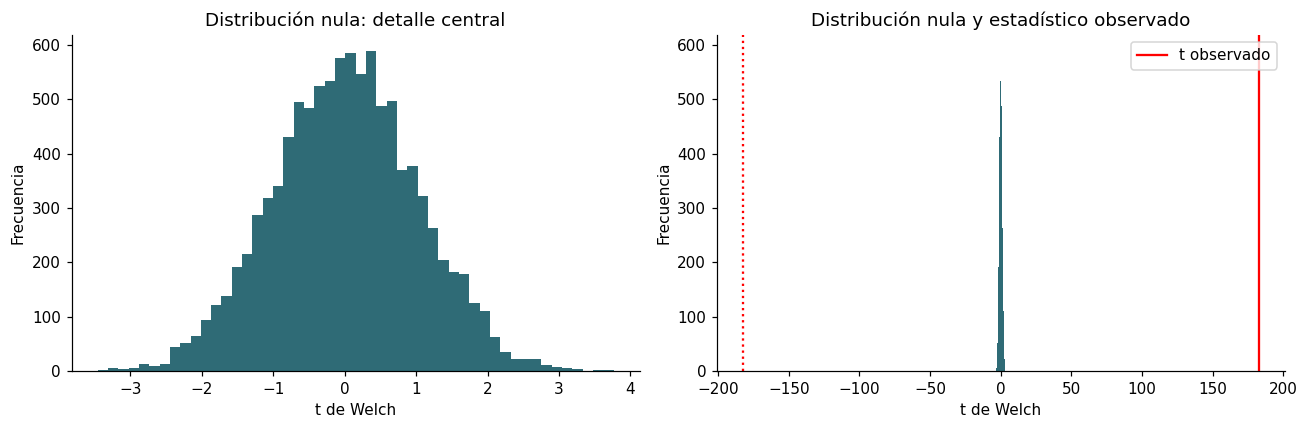

Decisiones concordantes al 5 %: True
Resolución mínima: 0.0001000; 0 excedencias. No se puede equiparar numéricamente este p al p paramétrico extremadamente pequeño.


In [5]:
valores,cuentas=np.unique(np.concatenate([h1,h0]),return_counts=True)
n1,n0=len(h1),len(h0)
suma_total=np.dot(cuentas,valores); cuadrados_total=np.dot(cuentas,valores**2)
t_perm=np.empty(B);gen=rng(200)
for inicio in range(0,B,100):
    w=gen.multivariate_hypergeometric(cuentas,n1,size=min(100,B-inicio))
    s1=w@valores; q1=w@(valores**2)
    s0=suma_total-s1;q0=cuadrados_total-q1
    var1=(q1-s1*s1/n1)/(n1-1);var0=(q0-s0*s0/n0)/(n0-1)
    t_perm[inicio:inicio+len(w)]=(s1/n1-s0/n0)/np.sqrt(var1/n1+var0/n0)
b_extremo=int(np.sum(np.abs(t_perm)>=abs(t_s1)))
p_perm=(b_extremo+1)/(B+1)
# Intervalo exacto para la probabilidad de excedencia del mecanismo Monte Carlo.
mc_inf=0 if b_extremo==0 else stats.beta.ppf(.025,b_extremo,B-b_extremo+1)
mc_sup=1 if b_extremo==B else stats.beta.ppf(.975,b_extremo+1,B-b_extremo)
permutacion=pd.DataFrame([dict(t_S1=t_s1,p_parametrico=p_s1,p_permutacion=p_perm,
    extremos=b_extremo,B=B,MC_inf=mc_inf,MC_sup=mc_sup)])
display(permutacion);permutacion.to_csv(OUT/'permutacion.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(t_perm,bins=50,color='#2f6b76');ax[0].set_title('Distribución nula: detalle central')
ax[1].hist(t_perm,bins=50,color='#2f6b76');ax[1].axvline(t_s1,color='red',label='t observado');ax[1].axvline(-abs(t_s1),color='red',ls=':');ax[1].legend();ax[1].set_title('Distribución nula y estadístico observado')
for a in ax:a.set_xlabel('t de Welch');a.set_ylabel('Frecuencia')
guardar_fig('permutacion_welch')
print('Decisiones concordantes al 5 %:',bool((p_s1<.05)==(p_perm<.05)))
print(f'Resolución mínima: {1/(B+1):.7f}; {b_extremo} excedencias. No se puede equiparar numéricamente este p al p paramétrico extremadamente pequeño.')


## 4 Estabilidad de cuatro correlaciones de S1

Se remuestrean pares completos mediante frecuencias multinomiales de pares únicos; nunca se remuestrean las dos columnas por separado. Se calculan 10.000 réplicas e IC percentil al 95 %. La correlación se calcula a partir de sumas ponderadas centradas para mantener precisión numérica.

Criterio descriptivo explícito: signo estable si el intervalo excluye cero; precisión alta bajo iid si su anchura es menor a 0,05. Ese umbral es una regla de reporte elegida para este proyecto, no una prueba estadística ni una garantía de validez externa.

,variable,n,r_S1,IC_inf,IC_sup,ancho,error_bootstrap,incluye_cero,estable_iid,B
0,TemperaturaMáxima / Temperatura3pm,141589,0.984503,0.984140,0.984854,0.000714,0.000183,False,True,10000
1,Presión9am / Presión3pm,130171,0.961326,0.960853,0.961807,0.000954,0.000242,False,True,10000
2,HorasSol / Nubosidad3pm,65253,-0.703930,-0.707700,-0.700160,0.007541,0.001912,False,True,10000
3,Humedad3pm / HorasSol,74497,-0.629130,-0.633592,-0.624498,0.009094,0.002326,False,True,10000


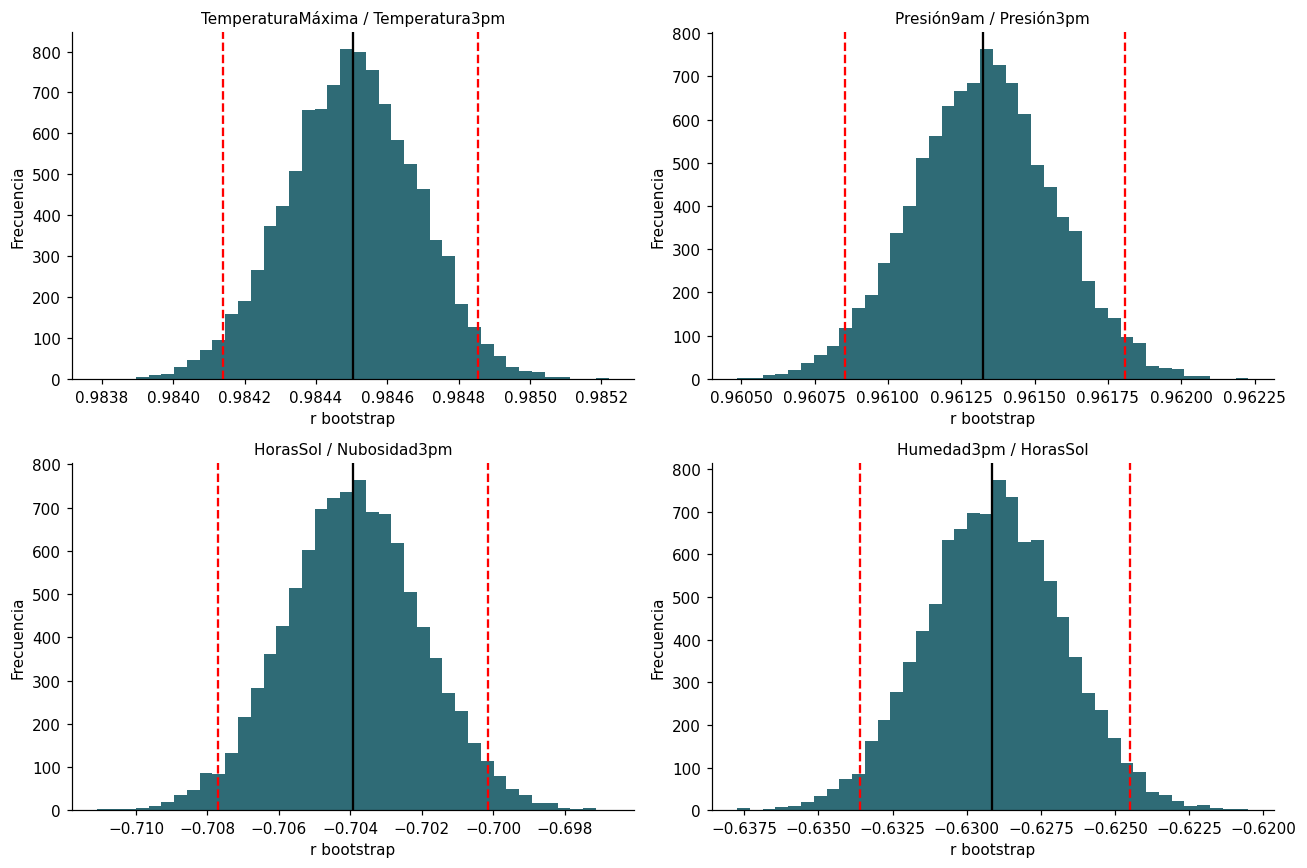

Correlaciones con signo estable y anchura <0,05 bajo iid: 4 de 4


In [6]:
def bootstrap_corr(pares,B,gen):
    # Centrado fijo: no cambia la correlación y evita cancelación en presiones ~1000 hPa.
    pares=pares-pares.mean(axis=0)
    uv,counts=np.unique(pares,axis=0,return_counts=True);n=counts.sum()
    x,y=uv.T;momentos=np.column_stack([x,y,x*x,y*y,x*y]);out=np.empty(B)
    for inicio in range(0,B,50):
        w=gen.multinomial(n,counts/n,size=min(50,B-inicio))
        a,b,c,d,e=(w@momentos).T
        out[inicio:inicio+len(w)]=(e-a*b/n)/np.sqrt((c-a*a/n)*(d-b*b/n))
    if not np.isfinite(out).all():raise ValueError('Réplicas de correlación degeneradas.')
    return out
corr_boot={};filas=[];fig,axes=plt.subplots(2,2,figsize=(12,8))
for i,((a,b),ax) in enumerate(zip(PAIRS,axes.flat)):
    pares=df[[a,b]].dropna().to_numpy(float)
    rep=bootstrap_corr(pares,B,rng(300+i));corr_boot[a+' / '+b]=rep
    li,ls=np.quantile(rep,[.025,.975]); r=np.corrcoef(pares.T)[0,1]
    filas.append(dict(variable=a+' / '+b,n=len(pares),r_S1=r,IC_inf=li,IC_sup=ls,
                      ancho=ls-li,error_bootstrap=rep.std(ddof=1),incluye_cero=bool(li<=0<=ls),
                      estable_iid=bool(not li<=0<=ls and ls-li<.05),B=B))
    ax.hist(rep,bins=40,color='#2f6b76');ax.axvline(r,color='black')
    ax.axvline(li,color='red',ls='--');ax.axvline(ls,color='red',ls='--')
    ax.set_title(a+' / '+b,fontsize=10);ax.set_xlabel('r bootstrap');ax.set_ylabel('Frecuencia')
correlaciones=pd.DataFrame(filas);display(correlaciones)
correlaciones.to_csv(OUT/'estabilidad_correlaciones.csv',index=False);guardar_fig('bootstrap_correlaciones')
print('Correlaciones con signo estable y anchura <0,05 bajo iid:',int(correlaciones.estable_iid.sum()),'de',len(correlaciones))


### 4.1 Comparación visual conjunta de los intervalos

El gráfico resume los IC bootstrap de las cuatro correlaciones en una escala común, con cero como referencia. Complementa los histogramas; no se necesitan exactamente cinco pares porque la consigna permite entre tres y cinco. Se mantienen 10.000 réplicas, frente a 3.000 en el ejemplo.

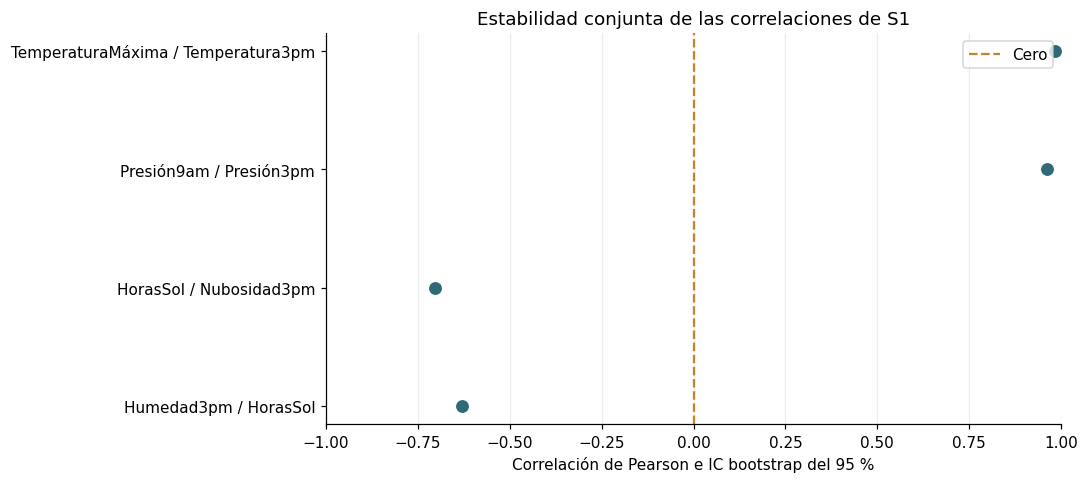

In [7]:
fig,ax=plt.subplots(figsize=(10,4.5))
for i,r in correlaciones.iterrows():
    color='#a4503e' if r.incluye_cero else '#2f6b76'
    ax.plot([r.IC_inf,r.IC_sup],[i,i],lw=3,color=color)
    ax.scatter(r.r_S1,i,color=color,s=55,zorder=3)
ax.axvline(0,color='#c0852f',ls='--',label='Cero')
ax.set_yticks(range(len(correlaciones)))
ax.set_yticklabels(correlaciones.variable)
ax.invert_yaxis();ax.set_xlim(-1,1)
ax.set_xlabel('Correlación de Pearson e IC bootstrap del 95 %')
ax.set_title('Estabilidad conjunta de las correlaciones de S1')
ax.grid(axis='x',alpha=.25);ax.legend()
guardar_fig('intervalos_correlaciones')


## 5 Simulación Monte Carlo para un horizonte de 30 días

Se explora la cantidad de días con lluvia en un horizonte hipotético de 30 días para planificar labores de campo. El horizonte y el evento de al menos 10 días son decisiones del escenario, no parámetros estimados. El modelo binomial usa exclusivamente la proporción de S1. Se compara con una cadena de Markov que usa las proporciones condicionales de la tabla de S1: P(lluvia mañana | lluvia hoy) y P(lluvia mañana | no lluvia hoy). El estado inicial usa la proporción global S1.

La cadena representa persistencia de primer orden como sensibilidad; combina localidades y estaciones, por lo que no es un modelo meteorológico validado. Se distinguen intervalos de simulación (variabilidad de escenarios) de IC para estimadores. Ninguno incorpora automáticamente incertidumbre de los parámetros. Se añade sensibilidad al IC clásico de p calculado en S1, manteniendo el modelo iid.


,modelo,iteraciones,media,sd,P025,P975,P99,prob_10_o_mas,error_MC_media,error_MC_prob
0,Binomial iid,10000,6.6959,2.274981,3.0,11.0,12.00,0.1124,0.022750,0.003159
1,Markov primer orden,10000,6.6010,3.093793,1.0,13.0,14.01,0.1739,0.030938,0.003790


Media teórica binomial: 6.725436554542067
Probabilidad teórica binomial >=10: 0.11480049697774743


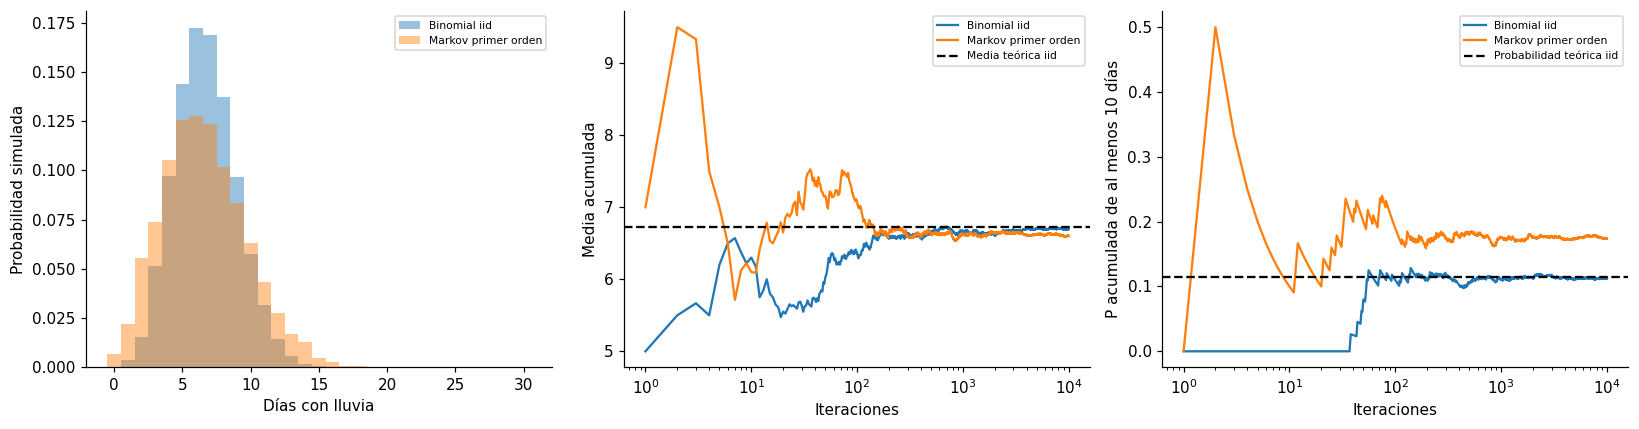

,modelo,k,media,prob
0,Binomial iid,100,6.3700,0.1100
1,Binomial iid,1000,6.6690,0.1110
2,Binomial iid,5000,6.6998,0.1114
3,Binomial iid,10000,6.6959,0.1124
4,Markov primer orden,100,7.0800,0.1900
5,Markov primer orden,1000,6.6100,0.1750
6,Markov primer orden,5000,6.6314,0.1746
7,Markov primer orden,10000,6.6010,0.1739


,p,media_teorica,prob_10_o_mas
0,0.222014,6.660407,0.109079
1,0.224181,6.725437,0.114800
2,0.226349,6.790466,0.120703


In [8]:
H=30;UMBRAL=10;p_global=df.LluviaMañana_bin.mean();gen=rng(400)
sim_iid=gen.binomial(H,p_global,size=B)
estado=rng(401).random(B)<p_global;sim_markov=np.zeros(B,dtype=int);gen=rng(402)
for dia in range(H):
    estado=gen.random(B)<np.where(estado,p_cond_si,p_cond_no)
    sim_markov+=estado
simulaciones={'Binomial iid':sim_iid,'Markov primer orden':sim_markov}
filas=[]
for nombre,v in simulaciones.items():
    prob=np.mean(v>=UMBRAL)
    filas.append(dict(modelo=nombre,iteraciones=B,media=v.mean(),sd=v.std(ddof=1),
        P025=np.quantile(v,.025),P975=np.quantile(v,.975),P99=np.quantile(v,.99),prob_10_o_mas=prob,
        error_MC_media=v.std(ddof=1)/np.sqrt(B),error_MC_prob=np.sqrt(prob*(1-prob)/B)))
montecarlo=pd.DataFrame(filas);display(montecarlo)
print('Media teórica binomial:',H*p_global)
print('Probabilidad teórica binomial >=10:',stats.binom.sf(UMBRAL-1,H,p_global))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for nombre,v in simulaciones.items():
    axes[0].hist(v,bins=np.arange(-.5,H+1.5),density=True,alpha=.45,label=nombre)
    acumulada=np.cumsum(v)/np.arange(1,B+1)
    axes[1].plot(np.arange(1,B+1),acumulada,label=nombre)
    prob_acum=np.cumsum(v>=UMBRAL)/np.arange(1,B+1)
    axes[2].plot(np.arange(1,B+1),prob_acum,label=nombre)
axes[1].axhline(H*p_global,color='black',ls='--',label='Media teórica iid')
axes[2].axhline(stats.binom.sf(UMBRAL-1,H,p_global),color='black',ls='--',label='Probabilidad teórica iid')
axes[0].set_xlabel('Días con lluvia');axes[0].set_ylabel('Probabilidad simulada')
axes[1].set_ylabel('Media acumulada');axes[2].set_ylabel('P acumulada de al menos 10 días')
for ax in axes[1:]:ax.set_xlabel('Iteraciones');ax.set_xscale('log')
for ax in axes:ax.legend(fontsize=7)
guardar_fig('montecarlo_convergencia')
convergencia=[]
for nombre,v in simulaciones.items():
    for k in [100,1000,5000,10000]:convergencia.append(dict(modelo=nombre,k=k,media=v[:k].mean(),prob=np.mean(v[:k]>=UMBRAL)))
display(pd.DataFrame(convergencia))
lim=base.loc[base.variable=='LluviaMañana_bin'].iloc[0]
sensibilidad_p=pd.DataFrame([dict(p=p,media_teorica=H*p,prob_10_o_mas=stats.binom.sf(UMBRAL-1,H,p))
    for p in [lim.clasico_inf,p_global,lim.clasico_sup]])
display(sensibilidad_p)
montecarlo.to_csv(OUT/'montecarlo.csv',index=False)
pd.DataFrame(convergencia).to_csv(OUT/'convergencia.csv',index=False)
sensibilidad_p.to_csv(OUT/'sensibilidad_p.csv',index=False)


### 5.1 Escenarios por horizonte de planificación

Se compara la proporción de días lluviosos en 7, 30, 90 y 365 días, manteniendo p de S1. La fila de 30 días reutiliza exactamente la simulación principal. Cada escenario nuevo utiliza una semilla propia y 10.000 iteraciones. Se reporta P(proporción de días lluviosos ≥ 1/3), comparable entre horizontes, y el percentil 99. Es distinto de la probabilidad de al menos 10 días de la simulación principal.

La dispersión de las proporciones iid debe disminuir al aumentar H, ya que su desviación teórica es sqrt[p(1-p)/H]. No se interpreta como diversificación real sin dependencia: un horizonte anual con p constante ignora estaciones, por lo que es una sensibilidad matemática, no una proyección climática anual.

Una frecuencia Monte Carlo de cero significa que no se observaron excedencias en 10.000 escenarios, no que el evento sea imposible. La tabla incluye la probabilidad binomial teórica: para horizontes con eventos muy raros, 10.000 iteraciones no bastan para estimar bien esa cola.

,horizonte,B,media_dias,media_proporcion,sd_proporcion,sd_teorica,P025,P975,P99,prob_al_menos_un_tercio,prob_teorica,error_MC_media
0,7,10000,1.5615,0.223071,0.158716,0.157627,0.000000,0.571429,0.571429,0.1917,1.920143e-01,0.001587
1,30,10000,6.6959,0.223197,0.075833,0.076141,0.100000,0.366667,0.400000,0.1124,1.148005e-01,0.000758
2,90,10000,20.1195,0.223550,0.044264,0.043960,0.144444,0.311111,0.333333,0.0117,1.154349e-02,0.000443
3,365,10000,81.8928,0.224364,0.021724,0.021829,0.183562,0.268493,0.276712,0.0000,9.731436e-07,0.000217


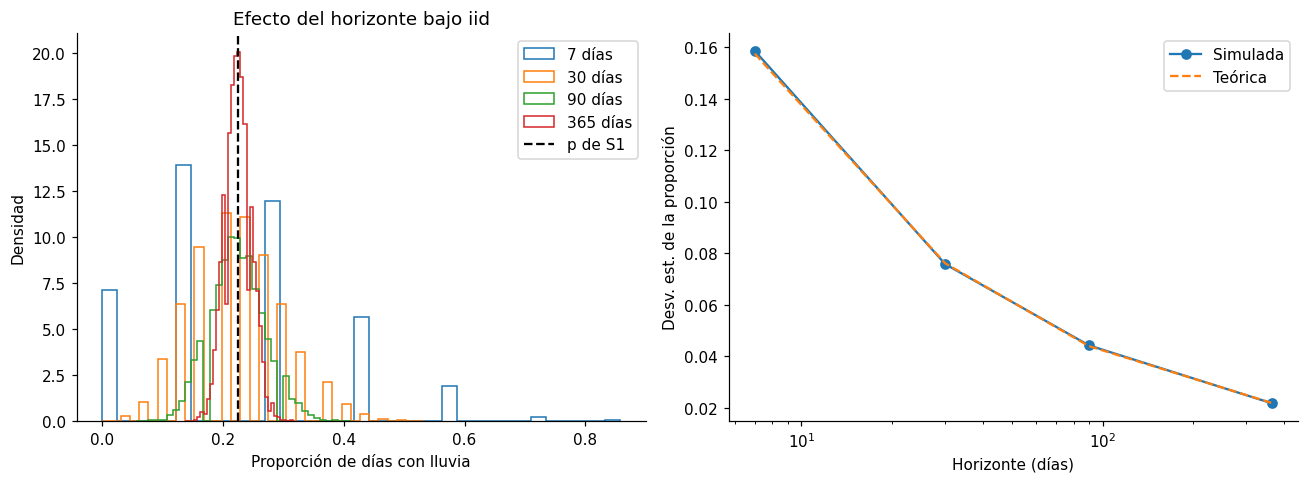

P99 del escenario principal:


,modelo,P99
0,Binomial iid,12.00
1,Markov primer orden,14.01


Al aumentar el horizonte disminuye la dispersión de las proporciones bajo p constante e independencia; no necesariamente disminuye el número absoluto de días lluviosos.


In [9]:
HORIZONTES=[7,30,90,365]
fraccion_umbral=1/3
filas_h=[];distribuciones_h={}
for h in HORIZONTES:
    conteos=sim_iid.copy() if h==H else rng(600+h).binomial(h,p_global,size=B)
    tasas=conteos/h;distribuciones_h[h]=tasas
    minimo=int(np.ceil(h*fraccion_umbral))
    filas_h.append(dict(horizonte=h,B=B,media_dias=conteos.mean(),media_proporcion=tasas.mean(),
        sd_proporcion=tasas.std(ddof=1),sd_teorica=np.sqrt(p_global*(1-p_global)/h),
        P025=np.quantile(tasas,.025),P975=np.quantile(tasas,.975),P99=np.quantile(tasas,.99),
        prob_al_menos_un_tercio=np.mean(conteos>=minimo),
        prob_teorica=stats.binom.sf(minimo-1,h,p_global),
        error_MC_media=tasas.std(ddof=1)/np.sqrt(B)))
escenarios_h=pd.DataFrame(filas_h)
display(escenarios_h)
escenarios_h.to_csv(OUT/'escenarios_horizonte.csv',index=False)
assert np.array_equal(distribuciones_h[30],sim_iid/30)
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
for h,tasas in distribuciones_h.items():
    ax[0].hist(tasas,bins=35,density=True,histtype='step',label=f'{h} días')
ax[0].axvline(p_global,color='black',ls='--',label='p de S1')
ax[0].set_xlabel('Proporción de días con lluvia');ax[0].set_ylabel('Densidad');ax[0].legend()
ax[0].set_title('Efecto del horizonte bajo iid')
ax[1].plot(escenarios_h.horizonte,escenarios_h.sd_proporcion,'o-',label='Simulada')
ax[1].plot(escenarios_h.horizonte,escenarios_h.sd_teorica,'--',label='Teórica')
ax[1].set_xscale('log');ax[1].set_xlabel('Horizonte (días)');ax[1].set_ylabel('Desv. est. de la proporción');ax[1].legend()
guardar_fig('montecarlo_horizontes')
print('P99 del escenario principal:')
display(montecarlo[['modelo','P99']])
print('Al aumentar el horizonte disminuye la dispersión de las proporciones bajo p constante e independencia; no necesariamente disminuye el número absoluto de días lluviosos.')


## 6 Robustez frente a extremos y estructura de los datos

Se compara cada media original con la media recortada al 1 % en cada cola. No se borran datos: es sensibilidad y cambia el estimando. El jackknife de eliminación individual cuantifica cuánto cambia la media al quitar cada registro e identifica fecha/localidad de las cinco observaciones de mayor influencia absoluta por variable.

Para evaluar composición geográfica se omite una localidad a la vez; esto no es un IC, sino sensibilidad a cobertura. Se añade bootstrap de conglomerados localidad-mes (10.000 réplicas) de las medias y proporción: se remuestrean grupos completos y se calcula la razón suma/conteo. Conserva la dependencia dentro de cada grupo, pero no entre meses o localidades; no es una corrección definitiva ni equivale a un bootstrap de bloques móviles. Su estimando y mecanismo difieren del bootstrap iid y deben interpretarse por separado.

,variable,media,media_recortada_1pct,cambio_recorte,max_cambio_jackknife,error_jackknife
0,TemperaturaMáxima,23.221348,23.217417,-0.003931,0.000194,0.018747
1,Humedad3pm,51.539116,51.517791,-0.021325,0.000366,0.055391
2,Presión3pm,1015.255889,1015.277074,0.021185,0.000293,0.019486
3,LluviaMañana_bin,0.224181,0.224181,0.000000,0.000005,0.001106


,variable,fila_csv,fecha,localidad,valor,cambio_media_al_omitir
0,TemperaturaMáxima,54756,2016-07-13 00:00:00,MountGinini,-4.8,0.000194
1,TemperaturaMáxima,54044,2014-08-01 00:00:00,MountGinini,-4.1,0.000189
2,TemperaturaMáxima,53698,2013-08-20 00:00:00,MountGinini,-3.8,0.000187
3,TemperaturaMáxima,53668,2013-07-21 00:00:00,MountGinini,-3.7,0.000187
4,TemperaturaMáxima,54404,2015-07-27 00:00:00,MountGinini,-3.2,0.000183
5,Humedad3pm,107943,2015-10-05 00:00:00,Woomera,0.0,0.000366
6,Humedad3pm,107953,2015-10-15 00:00:00,Woomera,0.0,0.000366
7,Humedad3pm,107617,2014-11-13 00:00:00,Woomera,0.0,0.000366
8,Humedad3pm,107228,2013-10-20 00:00:00,Woomera,0.0,0.000366
9,Humedad3pm,137754,2013-10-06 00:00:00,AliceSprings,1.0,0.000359


,variable,localidad_omitida,media_sin_localidad,media_original,cambio
52,Humedad3pm,AliceSprings,52.142244,51.539116,0.603128
195,LluviaMañana_bin,Woomera,0.227545,0.224181,0.003364
111,Presión3pm,Darwin,1015.429100,1015.255889,0.173211
23,TemperaturaMáxima,MountGinini,23.465823,23.221348,0.244475


,variable,r_original,r_sin_extremos,n_original,n_sin_extremos,cambio
0,TemperaturaMáxima / Temperatura3pm,0.984503,0.982619,141589,138403,-0.001884
1,Presión9am / Presión3pm,0.961326,0.956261,130171,126930,-0.005064
2,HorasSol / Nubosidad3pm,-0.703930,-0.702150,65253,64810,0.001780
3,Humedad3pm / HorasSol,-0.629130,-0.614858,74497,72720,0.014272


,variable,grupos,IC_grupos_inf,IC_grupos_sup,ancho_grupos,ratio_ancho_grupos_iid
0,TemperaturaMáxima,4769,23.044505,23.398761,0.354256,4.822283
1,Humedad3pm,4687,51.123116,51.945991,0.822875,3.743008
2,Presión3pm,4310,1015.132129,1015.375053,0.242923,3.176176
3,LluviaMañana_bin,4768,0.219938,0.228409,0.008471,1.958404


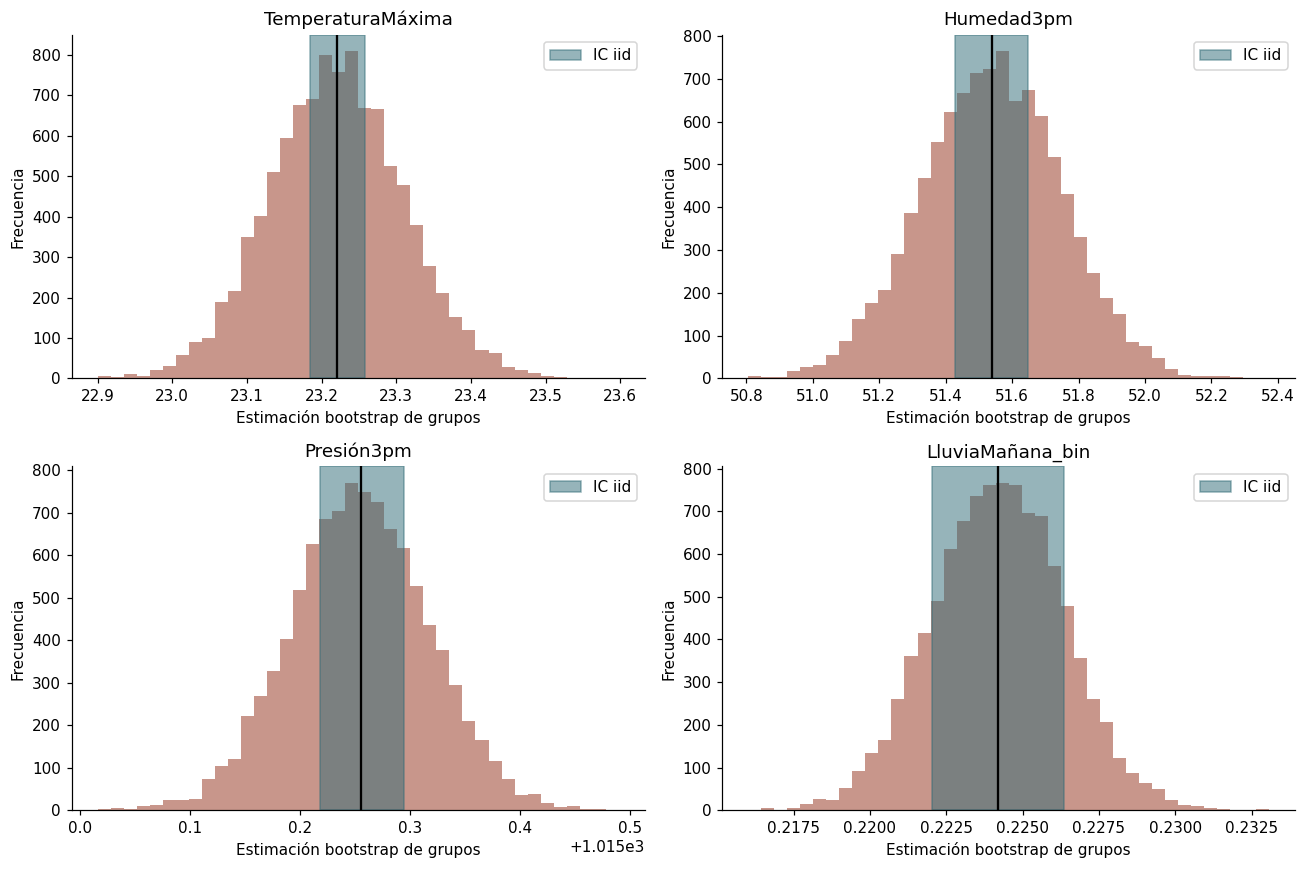

In [10]:
rob=[];influencias=[];geografia=[]
for c in PARAMS:
    serie=df[c].dropna();x=serie.to_numpy(float);m=x.mean();n=len(x)
    jack=(x.sum()-x)/(n-1);delta=jack-m
    rec=stats.trim_mean(x,.01) if not c.endswith('_bin') else m
    rob.append(dict(variable=c,media=m,media_recortada_1pct=rec,cambio_recorte=rec-m,
                    max_cambio_jackknife=np.max(np.abs(delta)),
                    error_jackknife=np.sqrt((n-1)/n*np.sum((jack-jack.mean())**2))))
    for pos in np.argsort(np.abs(delta))[-5:][::-1]:
        idx=serie.index[pos]
        influencias.append(dict(variable=c,fila_csv=int(idx)+2,fecha=str(df.loc[idx,'Fecha']),
            localidad=df.loc[idx,'Ubicación'],valor=x[pos],cambio_media_al_omitir=delta[pos]))
    for loc,g in df.groupby('Ubicación'):
        xx=g[c].dropna()
        if n>len(xx):geografia.append(dict(variable=c,localidad_omitida=loc,media_sin_localidad=(x.sum()-xx.sum())/(n-len(xx)),media_original=m))
robustez=pd.DataFrame(rob);influyentes=pd.DataFrame(influencias);geo=pd.DataFrame(geografia)
display(robustez);display(influyentes)
geo['cambio']=geo.media_sin_localidad-geo.media_original
display(geo.loc[geo.groupby('variable').cambio.apply(lambda x:x.abs().idxmax())])
robustez.to_csv(OUT/'robustez_medias.csv',index=False);influyentes.to_csv(OUT/'observaciones_influyentes.csv',index=False);geo.to_csv(OUT/'sensibilidad_localidades.csv',index=False)
# Correlaciones: retirar extremos marginales 1–99 % solo como sensibilidad.
rc=[]
for a,b in PAIRS:
    p=df[[a,b]].dropna();lo=p.quantile(.01);hi=p.quantile(.99)
    q=p.loc[p.ge(lo).all(axis=1)&p.le(hi).all(axis=1)]
    rc.append(dict(variable=a+' / '+b,r_original=p.corr().iloc[0,1],r_sin_extremos=q.corr().iloc[0,1],n_original=len(p),n_sin_extremos=len(q)))
rob_corr=pd.DataFrame(rc);rob_corr['cambio']=rob_corr.r_sin_extremos-rob_corr.r_original
display(rob_corr);rob_corr.to_csv(OUT/'robustez_correlaciones.csv',index=False)
# Grupos por localidad y mes calendario, con tamaño desigual explícito.
aux=df.assign(mes_bloque=df.Fecha.dt.to_period('M').astype(str))
filas=[];fig,axes=plt.subplots(2,2,figsize=(12,8))
for i,(c,ax) in enumerate(zip(PARAMS,axes.flat)):
    g=aux.groupby(['Ubicación','mes_bloque'])[c].agg(['sum','count']);g=g[g['count']>0]
    sumas=g['sum'].to_numpy();cuentas=g['count'].to_numpy();k=len(g);gen=rng(500+i)
    reps=np.empty(B)
    for inicio in range(0,B,50):
        w=gen.multinomial(k,np.full(k,1/k),size=min(50,B-inicio))
        reps[inicio:inicio+len(w)]=(w@sumas)/(w@cuentas)
    li,ls=np.quantile(reps,[.025,.975]);iid=parametros.loc[parametros.variable==c].iloc[0]
    filas.append(dict(variable=c,grupos=k,IC_grupos_inf=li,IC_grupos_sup=ls,
        ancho_grupos=ls-li,ratio_ancho_grupos_iid=(ls-li)/iid.ancho_percentil))
    ax.hist(reps,bins=40,color='#a4503e',alpha=.6);ax.axvline(iid.estimacion_S1,color='black')
    ax.axvspan(iid.percentil_inf,iid.percentil_sup,color='#2f6b76',alpha=.5,label='IC iid')
    ax.set_title(c);ax.set_xlabel('Estimación bootstrap de grupos');ax.set_ylabel('Frecuencia');ax.legend()
bloques=pd.DataFrame(filas);display(bloques)
bloques.to_csv(OUT/'sensibilidad_conglomerados.csv',index=False);guardar_fig('sensibilidad_dependencia')


### 6.1 Estimadores alternativos y sensibilidad de la hipótesis original

Se comparan media, mediana, media recortada al 5 % por cola y media tras excluir el 1 % superior. Son estimandos distintos: una diferencia entre media y mediana no se interpreta como error de la media. La exclusión unilateral puede desplazar incluso una distribución simétrica.

Se repite Welch en cuatro escenarios: casos completos originales, sin duplicados de las variables originales, humedad dentro de P1–P99 y dentro de P5–P95. Los umbrales se calculan sobre la humedad agrupada de ambos grupos, sin seleccionarlos según el resultado de la prueba. Se conservan los originales para no confundir una sensibilidad con una limpieza definitiva. Se reportan diferencia, tamaño del efecto y p; con muestras grandes el rechazo puede persistir aunque cambie la magnitud.

,variable,media,mediana,media_recortada_5pct,media_sin_top1pct,umbral_P99,n_sin_top1pct
0,TemperaturaMáxima,23.221348,22.6,23.104943,23.033778,40.1,142765
1,Humedad3pm,51.539116,52.0,51.423139,51.253770,98.0,140119
2,Presión3pm,1015.255889,1015.2,1015.264410,1015.075576,1031.6,129149


,escenario,n_si,n_no,media_si,media_no,diferencia_pp,t,p,p_reporte,d_cohen,rechaza_H0,cambio_diferencia_pp
0,Original,30913,107670,68.800019,46.510625,22.289394,182.607693,0.0,<0.001 (posible subdesbordamiento),1.197511,True,0.000000
1,Sin duplicados originales,30913,107670,68.800019,46.510625,22.289394,182.607693,0.0,<0.001 (posible subdesbordamiento),1.197511,True,0.000000
2,Humedad P1–P99,30183,106221,68.138720,46.957626,21.181094,176.008952,0.0,<0.001 (posible subdesbordamiento),1.169859,True,-1.108300
3,Humedad P5–P95,25336,100021,63.951255,48.405575,15.545680,138.290117,0.0,<0.001 (posible subdesbordamiento),0.965804,True,-6.743714


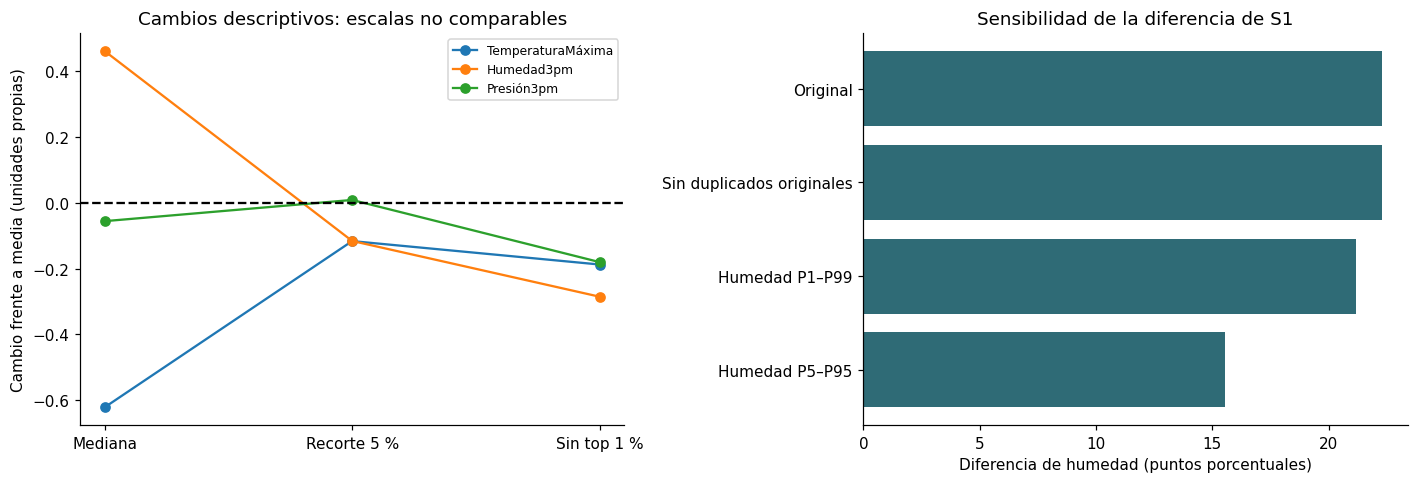

Duplicados originales eliminados: 0
Mismo signo de diferencia en todos los escenarios: True
Decisión al 5 % conservada en todos los escenarios: True
Esto evalúa extremos y duplicados, no resuelve dependencia, confusión geográfica ni sesgo por faltantes.


In [11]:
alt=[]
for c in PARAMS[:3]:
    x=df[c].dropna().to_numpy(float);m=x.mean();cap=np.quantile(x,.99)
    alt.append(dict(variable=c,media=m,mediana=np.median(x),media_recortada_5pct=stats.trim_mean(x,.05),
        media_sin_top1pct=x[x<=cap].mean(),umbral_P99=cap,n_sin_top1pct=int(np.sum(x<=cap))))
estimadores_alt=pd.DataFrame(alt);display(estimadores_alt)
estimadores_alt.to_csv(OUT/'estimadores_alternativos.csv',index=False)
# Eliminar duplicados solo usando las columnas originales, antes de derivadas.
# La traducción de nombres es uno a uno, por lo que se conserva el orden de las 23 originales.
originales=df.columns[:len(raw.columns)].tolist()
assert len(originales)==len(raw.columns)
sin_dup=df.drop_duplicates(subset=originales)
completos=df.loc[df.LluviaMañana.isin(['Sí','No'])].dropna(subset=['Humedad3pm'])
escenarios_w={'Original':completos,
    'Sin duplicados originales':sin_dup.loc[sin_dup.LluviaMañana.isin(['Sí','No'])].dropna(subset=['Humedad3pm'])}
for q,nombre in [(.01,'Humedad P1–P99'),(.05,'Humedad P5–P95')]:
    li,ls=completos.Humedad3pm.quantile([q,1-q])
    escenarios_w[nombre]=completos.loc[completos.Humedad3pm.between(li,ls)]
filas_w=[]
for nombre,d in escenarios_w.items():
    a=d.loc[d.LluviaMañana=='Sí','Humedad3pm'].to_numpy()
    b=d.loc[d.LluviaMañana=='No','Humedad3pm'].to_numpy()
    tt,pp=stats.ttest_ind(a,b,equal_var=False)
    sp=np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2))
    diferencia=a.mean()-b.mean()
    filas_w.append(dict(escenario=nombre,n_si=len(a),n_no=len(b),media_si=a.mean(),media_no=b.mean(),
        diferencia_pp=diferencia,t=tt,p=pp,p_reporte='<0.001 (posible subdesbordamiento)' if pp<.001 else f'{pp:.6f}',
        d_cohen=diferencia/sp,rechaza_H0=bool(pp<.05)))
sens_welch=pd.DataFrame(filas_w)
sens_welch['cambio_diferencia_pp']=sens_welch.diferencia_pp-sens_welch.iloc[0].diferencia_pp
display(sens_welch)
sens_welch.to_csv(OUT/'robustez_welch.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
for i,r in estimadores_alt.iterrows():
    cambios=np.array([r.mediana,r.media_recortada_5pct,r.media_sin_top1pct])-r.media
    ax[0].plot(['Mediana','Recorte 5 %','Sin top 1 %'],cambios,'o-',label=r.variable)
ax[0].axhline(0,color='black',ls='--');ax[0].set_ylabel('Cambio frente a media (unidades propias)')
ax[0].set_title('Cambios descriptivos: escalas no comparables');ax[0].legend(fontsize=8)
ax[1].barh(sens_welch.escenario,sens_welch.diferencia_pp,color='#2f6b76');ax[1].invert_yaxis()
ax[1].set_xlabel('Diferencia de humedad (puntos porcentuales)');ax[1].set_title('Sensibilidad de la diferencia de S1')
guardar_fig('robustez_estimadores_welch')
print('Duplicados originales eliminados:',len(df)-len(sin_dup))
print('Mismo signo de diferencia en todos los escenarios:',bool((sens_welch.diferencia_pp>0).all()))
print('Decisión al 5 % conservada en todos los escenarios:',bool((sens_welch.rechaza_H0==sens_welch.iloc[0].rechaza_H0).all()))
print('Esto evalúa extremos y duplicados, no resuelve dependencia, confusión geográfica ni sesgo por faltantes.')


## 7 Reporte de resultados validados para S3

Se exporta una síntesis verificable. La estabilidad iid y la sensibilidad a la dependencia se reportan por separado: un intervalo estrecho iid no basta para declarar un parámetro robusto en todas las condiciones. Las observaciones influyentes no se clasifican como errores sin revisión. Para S3 se recomienda validar por tiempo y localidad, ajustar imputación solo con entrenamiento y evaluar sensibilidad a estaciones y cobertura.

Los resultados son evidencia exploratoria para priorizar variables; no establecen umbrales agrícolas operativos ni causalidad. Antes de una decisión de riego se necesitarían suelo, cultivo, costos y una validación predictiva local.

In [12]:
valid=[]
for _,r in parametros.iterrows():
    bl=bloques.loc[bloques.variable==r.variable].iloc[0]
    ro=robustez.loc[robustez.variable==r.variable].iloc[0]
    sensible=bl.ratio_ancho_grupos_iid>1.10  # Regla descriptiva; se exporta además la razón continua.
    valid.append(dict(tipo='parametro',variable=r.variable,estimacion=r.estimacion_S1,
        IC_inf=r.BCa_inf,IC_sup=r.BCa_sup,metodo='BCa iid',
        diagnostico='Incertidumbre sensible a grupos' if sensible else 'Comparar supuestos de dependencia',
        recomendacion='Conservar estimación; validar dependencia y cobertura antes de generalizar',
        ratio_ancho_grupos_iid=bl.ratio_ancho_grupos_iid,cambio_recorte=ro.cambio_recorte))
for _,r in correlaciones.iterrows():
    rr=rob_corr.loc[rob_corr.variable==r.variable].iloc[0]
    valid.append(dict(tipo='correlacion',variable=r.variable,estimacion=r.r_S1,
        IC_inf=r.IC_inf,IC_sup=r.IC_sup,metodo='Percentil iid pareado',
        diagnostico='Signo y precisión estables bajo iid' if r.estable_iid else 'Requiere cautela bajo iid',
        recomendacion='Evaluar por localidad y estación; evitar redundancia de predictores',cambio_recorte=rr.cambio))
valid.append(dict(tipo='hipotesis',variable='Humedad3pm según lluvia mañana',estimacion=t_s1,
    metodo='Permutación Welch',diagnostico=f'p permutación={p_perm:.7g}; p paramétrico '+('<0.001; posible subdesbordamiento' if p_s1<.001 else f'{p_s1:.6g}'),
    recomendacion='Concordancia no resuelve falta de intercambiabilidad temporal/espacial'))
for _,r in sens_welch.iterrows():
    valid.append(dict(tipo='sensibilidad_hipotesis',variable=r.escenario,estimacion=r.diferencia_pp,
        metodo='Welch tras perturbación',diagnostico=f'd={r.d_cohen:.3f}; cambio={r.cambio_diferencia_pp:.3f} pp',
        recomendacion='Conservar magnitud y revisar dependencia; no seleccionar limpieza por valor p'))
for _,r in montecarlo.iterrows():
    valid.append(dict(tipo='simulacion',variable=r.modelo,estimacion=r.media,
        metodo='Monte Carlo 30 días',diagnostico=f'P99={r.P99:.1f} días; P(>=10)={r.prob_10_o_mas:.4f}',
        recomendacion='Escenario hipotético; validar temporalmente antes de decisión operativa'))
for _,r in escenarios_h.iterrows():
    valid.append(dict(tipo='sensibilidad_horizonte',variable=f'{int(r.horizonte)} días',estimacion=r.media_proporcion,
        metodo='Binomial iid',diagnostico=f'SD proporción={r.sd_proporcion:.5f}; P99={r.P99:.4f}',
        recomendacion='Comparación matemática bajo p constante; no extrapolar a calendario agrícola'))
validados=pd.DataFrame(valid);display(validados)
validados.to_csv(OUT/'resultados_validados.csv',index=False)
np.savez_compressed(OUT/'distribuciones_remuestreo.npz',
    **{'media_'+str(i):boots[c] for i,c in enumerate(PARAMS)},
    **{'corr_'+str(i):v for i,v in enumerate(corr_boot.values())},
    t_permutacion=t_perm,sim_iid=sim_iid,sim_markov=sim_markov,
    **{'horizonte_'+str(h):v for h,v in distribuciones_h.items()})
metadatos=dict(semilla=SEED,B=B,dataset_sha256=hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest(),
    python=sys.version,numpy=np.__version__,pandas=pd.__version__,scipy=scipy.__version__,
    parametros=PARAMS,correlaciones=PAIRS)
(OUT/'metadatos.json').write_text(json.dumps(metadatos,ensure_ascii=False,indent=2))
assert len(t_perm)==B and all(len(v)==B for v in boots.values()) and all(len(v)==B for v in corr_boot.values())
assert np.isfinite(parametros[['BCa_inf','BCa_sup']].to_numpy()).all()
print('Resultados guardados en:',OUT.resolve())
print('Para el repositorio: conservar S1, ubicar este notebook en S2 y añadir resultados_S2/resultados_validados.csv.')
print('El informe técnico PDF de máximo 7 páginas debe redactarse con las tablas y limitaciones de esta ejecución.')


,tipo,variable,estimacion,IC_inf,IC_sup,metodo,diagnostico,recomendacion,ratio_ancho_grupos_iid,cambio_recorte
0,parametro,TemperaturaMáxima,23.221348,23.184943,23.258405,BCa iid,Incertidumbre sensible a grupos,Conservar estimación; validar dependencia y co...,4.822283,-0.003931
1,parametro,Humedad3pm,51.539116,51.427561,51.646831,BCa iid,Incertidumbre sensible a grupos,Conservar estimación; validar dependencia y co...,3.743008,-0.021325
2,parametro,Presión3pm,1015.255889,1015.217939,1015.294432,BCa iid,Incertidumbre sensible a grupos,Conservar estimación; validar dependencia y co...,3.176176,0.021185
3,parametro,LluviaMañana_bin,0.224181,0.222034,0.226354,BCa iid,Incertidumbre sensible a grupos,Conservar estimación; validar dependencia y co...,1.958404,0.000000
4,correlacion,TemperaturaMáxima / Temperatura3pm,0.984503,0.984140,0.984854,Percentil iid pareado,Signo y precisión estables bajo iid,Evaluar por localidad y estación; evitar redun...,NaN,-0.001884
5,correlacion,Presión9am / Presión3pm,0.961326,0.960853,0.961807,Percentil iid pareado,Signo y precisión estables bajo iid,Evaluar por localidad y estación; evitar redun...,NaN,-0.005064
6,correlacion,HorasSol / Nubosidad3pm,-0.703930,-0.707700,-0.700160,Percentil iid pareado,Signo y precisión estables bajo iid,Evaluar por localidad y estación; evitar redun...,NaN,0.001780
7,correlacion,Humedad3pm / HorasSol,-0.629130,-0.633592,-0.624498,Percentil iid pareado,Signo y precisión estables bajo iid,Evaluar por localidad y estación; evitar redun...,NaN,0.014272
8,hipotesis,Humedad3pm según lluvia mañana,182.607693,NaN,NaN,Permutación Welch,p permutación=9.999e-05; p paramétrico <0.001;...,Concordancia no resuelve falta de intercambiab...,NaN,NaN
9,sensibilidad_hipotesis,Original,22.289394,NaN,NaN,Welch tras perturbación,d=1.198; cambio=0.000 pp,Conservar magnitud y revisar dependencia; no s...,NaN,NaN


Resultados guardados en: C:\Users\felip\resultados_S2
Para el repositorio: conservar S1, ubicar este notebook en S2 y añadir resultados_S2/resultados_validados.csv.
El informe técnico PDF de máximo 7 páginas debe redactarse con las tablas y limitaciones de esta ejecución.


## 8 Interpretación crítica de la ejecución

- **Parámetros:** los IC clásicos, percentil y BCa son cercanos bajo iid. Al recortar 1 % por cola, las medias cambian aproximadamente −0,004 °C en temperatura máxima, −0,021 puntos porcentuales en humedad y +0,021 hPa en presión. Estos pequeños cambios descriptivos no prueban validez del supuesto de independencia.
- **Dependencia:** las anchuras de los intervalos por grupos localidad-mes son aproximadamente 4,82, 3,74 y 3,18 veces las anchuras iid para temperatura, humedad y presión; para la proporción son 1,96 veces. La incertidumbre es sensible a la unidad de remuestreo.
- **Welch:** la conclusión al 5 % coincide con la permutación. No hubo excedencias en 10.000 permutaciones, por lo que el p corregido es 1/10.001 ≈ 0,000100. El p paramétrico mostrado como 0 corresponde a subdesbordamiento numérico, no a probabilidad exactamente cero. La concordancia no resuelve la intercambiabilidad de etiquetas ni la dependencia. Al restringir la humedad a P5–P95, la diferencia disminuye de 22,29 a 15,55 puntos porcentuales. Se conserva el signo y el rechazo de H₀, pero la magnitud es sensible al recorte
- **Correlaciones:** las cuatro mantienen su signo y tienen IC iid estrechos. La mayor variación al retirar extremos ocurre en humedad/horas de sol (aproximadamente +0,014 en r), sin invertir su signo. Las relaciones entre mediciones próximas de temperatura y presión sugieren redundancia para un modelo posterior; estabilidad no implica información predictiva adicional.
- **Monte Carlo:** el modelo iid produce una media de 6,70 días lluviosos en 30 días y una probabilidad de 11,24 % de al menos 10 días; la cadena produce una media de 6,60 y una probabilidad de 17,39 %. La dispersión aumenta de 2,27 a 3,09 días al representar persistencia. La diferencia entre modelos es mayor que los errores Monte Carlo de esas probabilidades (aproximadamente 0,32 y 0,38 puntos porcentuales), lo que indica sensibilidad al escenario, no simple ruido de simulación. Las medias similares no implican riesgos extremos similares.
- **Convergencia:** se muestran medias y probabilidades acumuladas junto con resultados a 100, 1.000, 5.000 y 10.000 iteraciones. La precisión final se cuantifica mediante errores Monte Carlo; la estabilización gráfica no demuestra que el modelo represente adecuadamente el clima real.

**Entrada para S3:** mantener las asociaciones como evidencia exploratoria y las estimaciones puntuales como referencias del archivo; no presentar los IC iid como incertidumbre definitiva. Priorizar validación temporal y por localidad, revisar las filas influyentes exportadas sin eliminarlas automáticamente y evaluar faltantes y estaciones. La decisión agrícola exige un modelo local validado y costos explícitos de falsas alertas y lluvias no anticipadas.


In [13]:
print('PARÁMETROS Y DEPENDENCIA')
for _,r in parametros.iterrows():
    bl=bloques.loc[bloques.variable==r.variable].iloc[0]
    print(f'{r.variable}: ancho BCa/clásico={r.ratio_BCa_clasico:.3f}; ancho grupos/iid={bl.ratio_ancho_grupos_iid:.2f}.')
print('La concordancia iid no demuestra independencia ni representatividad.')
print('PERMUTACIÓN')
print(f'{b_extremo} excedencias de {B}; p corregido={p_perm:.7f}.')
print('CORRELACIONES')
print(f'{int(correlaciones.estable_iid.sum())} de {len(correlaciones)} con signo y precisión estables bajo el criterio iid declarado.')
print('WELCH ANTE EXTREMOS')
print(f'Diferencias entre {sens_welch.diferencia_pp.min():.2f} y {sens_welch.diferencia_pp.max():.2f} pp; no se interpreta como corrección causal.')
print('MONTE CARLO')
for _,r in montecarlo.iterrows():print(f'{r.modelo}: media={r.media:.2f} días; SD={r.sd:.2f}; P99={r.P99:.0f}; P(>=10)={r.prob_10_o_mas:.2%}.')
print('S3: validar por tiempo, localidad y estación; revisar influyentes sin borrarlos automáticamente; definir costos y datos agronómicos antes de decisiones de riego.')
print('El informe previo conserva resultados centrales, pero debe incorporar los nuevos escenarios y la sensibilidad de Welch si se presentan como parte de la entrega final.')


PARÁMETROS Y DEPENDENCIA
TemperaturaMáxima: ancho BCa/clásico=1.000; ancho grupos/iid=4.82.
Humedad3pm: ancho BCa/clásico=1.010; ancho grupos/iid=3.74.
Presión3pm: ancho BCa/clásico=1.001; ancho grupos/iid=3.18.
LluviaMañana_bin: ancho BCa/clásico=0.997; ancho grupos/iid=1.96.
La concordancia iid no demuestra independencia ni representatividad.
PERMUTACIÓN
0 excedencias de 10000; p corregido=0.0001000.
CORRELACIONES
4 de 4 con signo y precisión estables bajo el criterio iid declarado.
WELCH ANTE EXTREMOS
Diferencias entre 15.55 y 22.29 pp; no se interpreta como corrección causal.
MONTE CARLO
Binomial iid: media=6.70 días; SD=2.27; P99=12; P(>=10)=11.24%.
Markov primer orden: media=6.60 días; SD=3.09; P99=14; P(>=10)=17.39%.
S3: validar por tiempo, localidad y estación; revisar influyentes sin borrarlos automáticamente; definir costos y datos agronómicos antes de decisiones de riego.
El informe previo conserva resultados centrales, pero debe incorporar los nuevos escenarios y la sensibi